# Model Interpretation

This notebook examines the predictors underlying the M3 forecasting models. Interpretation focuses on Ridge coefficients, Random Forest feature importance, and SHAP values for Gradient Boosting.

## 1. Ridge Regression Coefficients

Standardised Ridge coefficients are examined across the expanding forecasting windows. Their magnitude indicates the relative contribution of each predictor, while the sign indicates its association with predicted GDP growth.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor

In [2]:
dataset_m3 = pd.read_csv(
    "../data/processed/dataset_m3.csv"
)

dataset_m3["quarter"] = pd.PeriodIndex(
    dataset_m3["quarter"],
    freq="Q"
)

dataset_m3.head()

,quarter,gdp_qoq,bank_rate_m1,bank_rate_m2,bank_rate_m3,consumer_confidence_m1,consumer_confidence_m2,consumer_confidence_m3,cpi_inflation_m1,cpi_inflation_m2,retail_sales_m1,retail_sales_m2,oecd_cli_m1,gdp_monthly_m1,services_m1,industrial_production_m1,construction_m1,unemployment_rate_m1,vacancies_thousands_m1,wage_growth_m1
0,2006Q1,0.4,4.50,4.50,4.50,-3.0,-4.0,-7.0,1.9,2.0,-0.4,0.0,100.5471,-0.4,-0.2,-1.5,0.6,5.2,613.0,4.2
1,2006Q2,0.3,4.50,4.50,4.50,-4.0,-5.0,-4.0,2.0,2.2,0.0,0.5,101.0458,-0.4,-0.5,-0.1,-0.2,5.4,597.0,5.3
2,2006Q3,0.2,4.50,4.75,4.75,-4.0,-8.0,-7.0,2.4,2.5,-0.3,-0.1,101.4845,-0.5,-0.5,-1.0,-0.3,5.5,611.0,5.0
3,2006Q4,0.4,4.75,5.00,5.00,-5.0,-7.0,-8.0,2.4,2.7,1.1,0.3,102.1039,-0.6,-0.5,-1.3,0.2,5.4,619.0,4.0
4,2007Q1,1.1,5.25,5.25,5.25,-7.0,-8.0,-8.0,2.7,2.8,-1.2,1.3,102.7589,0.0,0.1,-0.1,0.0,5.5,629.0,5.4


In [3]:
m3_feature_cols = [
    col for col in dataset_m3.columns
    if col not in ["quarter", "gdp_qoq"]
]

print("Number of M3 features:", len(m3_feature_cols))
print(m3_feature_cols)

Number of M3 features: 18
['bank_rate_m1', 'bank_rate_m2', 'bank_rate_m3', 'consumer_confidence_m1', 'consumer_confidence_m2', 'consumer_confidence_m3', 'cpi_inflation_m1', 'cpi_inflation_m2', 'retail_sales_m1', 'retail_sales_m2', 'oecd_cli_m1', 'gdp_monthly_m1', 'services_m1', 'industrial_production_m1', 'construction_m1', 'unemployment_rate_m1', 'vacancies_thousands_m1', 'wage_growth_m1']


In [4]:
ridge_coef_results = []

evaluation_quarters = dataset_m3[
    dataset_m3["quarter"] >= pd.Period("2017Q1", freq="Q")
]["quarter"]

for forecast_quarter in evaluation_quarters:

    ridge_train = dataset_m3[
        dataset_m3["quarter"] < forecast_quarter
    ].copy()

    X_train = ridge_train[m3_feature_cols]
    y_train = ridge_train["gdp_qoq"]

    ridge_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge())
    ])

    param_grid = {
        "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000, 10000]
    }

    tscv = TimeSeriesSplit(n_splits=5)

    ridge_search = GridSearchCV(
        estimator=ridge_pipeline,
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_mean_squared_error"
    )

    ridge_search.fit(X_train, y_train)

    best_model = ridge_search.best_estimator_
    ridge_coefficients = best_model.named_steps["ridge"].coef_

    result = {
        "quarter": forecast_quarter,
        "alpha": ridge_search.best_params_["ridge__alpha"]
    }

    for feature, coefficient in zip(
        m3_feature_cols,
        ridge_coefficients
    ):
        result[feature] = coefficient

    ridge_coef_results.append(result)

ridge_coef_results = pd.DataFrame(ridge_coef_results)

display(ridge_coef_results.head())
print("Number of coefficient windows:", len(ridge_coef_results))

,quarter,alpha,bank_rate_m1,bank_rate_m2,bank_rate_m3,consumer_confidence_m1,consumer_confidence_m2,consumer_confidence_m3,cpi_inflation_m1,cpi_inflation_m2,retail_sales_m1,retail_sales_m2,oecd_cli_m1,gdp_monthly_m1,services_m1,industrial_production_m1,construction_m1,unemployment_rate_m1,vacancies_thousands_m1,wage_growth_m1
0,2017Q1,1.0,-0.285142,-0.001100,0.233137,0.115489,0.101688,0.006489,0.107536,-0.210202,0.048615,0.024862,0.408611,-0.033741,0.156968,0.045815,-0.056638,0.329773,-0.008885,0.120071
1,2017Q2,100.0,-0.032566,-0.016740,-0.005589,0.060644,0.061944,0.046362,-0.012642,-0.017143,-0.002220,0.015303,0.130962,0.041099,0.051518,-0.006738,0.026120,0.034068,-0.005880,0.011813
2,2017Q3,1000.0,-0.006018,-0.003777,-0.002184,0.015210,0.015551,0.013422,-0.008200,-0.008783,0.000308,0.002298,0.022411,0.009526,0.010384,0.000203,0.008319,-0.000377,0.005144,0.001316
3,2017Q4,1000.0,-0.006254,-0.004001,-0.002398,0.015356,0.015731,0.013601,-0.008147,-0.008652,0.000228,0.002586,0.022680,0.009647,0.010495,0.000335,0.008216,-0.000836,0.005514,0.001290
4,2018Q1,1000.0,-0.006563,-0.004250,-0.002632,0.015576,0.015890,0.013711,-0.007928,-0.008405,0.000198,0.002602,0.022954,0.009716,0.010544,0.000555,0.008100,-0.001431,0.006070,0.001356


Number of coefficient windows: 37


In [5]:
ridge_coef_results.to_csv(
    "../data/results/ridge_m3_coefficients.csv",
    index=False
)

In [6]:
coef_cols = [
    col for col in ridge_coef_results.columns
    if col not in ["quarter", "alpha"]
]

In [7]:
ridge_coef_summary = pd.DataFrame({
    "mean_coef": ridge_coef_results[coef_cols].mean(),
    "mean_abs_coef": ridge_coef_results[coef_cols].abs().mean(),
    "positive_pct": (
        (ridge_coef_results[coef_cols] > 0).mean() * 100
    ),
    "negative_pct": (
        (ridge_coef_results[coef_cols] < 0).mean() * 100
    )
})

ridge_coef_summary = (
    ridge_coef_summary
    .sort_values("mean_abs_coef", ascending=False)
)

display(ridge_coef_summary.round(3))

,mean_coef,mean_abs_coef,positive_pct,negative_pct
services_m1,1.551,1.551,100.000,0.000
bank_rate_m3,0.924,0.929,62.162,37.838
bank_rate_m2,-0.780,0.780,0.000,100.000
gdp_monthly_m1,-0.056,0.653,70.270,29.730
construction_m1,0.622,0.625,97.297,2.703
unemployment_rate_m1,-0.574,0.617,21.622,78.378
vacancies_thousands_m1,-0.513,0.529,29.730,70.270
bank_rate_m1,-0.443,0.451,5.405,94.595
cpi_inflation_m2,-0.433,0.433,0.000,100.000
oecd_cli_m1,0.385,0.385,100.000,0.000


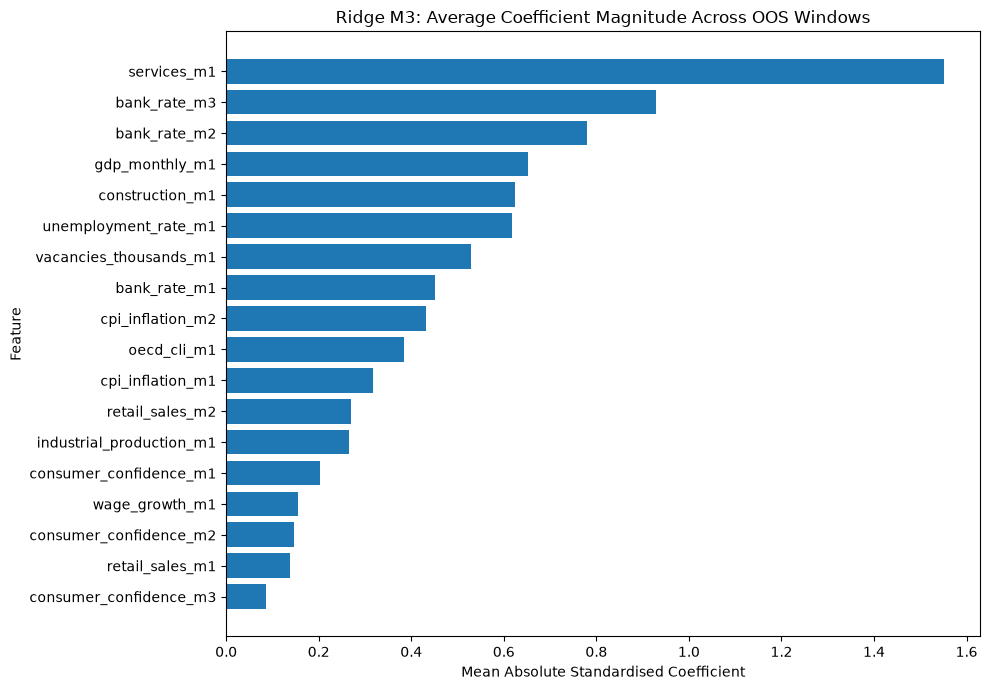

In [8]:
plt.figure(figsize=(10, 7))

plot_data = (
    ridge_coef_summary
    .sort_values("mean_abs_coef", ascending=True)
)

plt.barh(
    plot_data.index,
    plot_data["mean_abs_coef"]
)

plt.xlabel("Mean Absolute Standardised Coefficient")
plt.ylabel("Feature")
plt.title("Ridge M3: Average Coefficient Magnitude Across OOS Windows")

plt.tight_layout()
plt.savefig(
    "../figures/ridge_m3_coefficient_magnitude.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Ridge Summary

Services output has the largest average coefficient magnitude and remains positively associated with GDP growth across all forecasting windows. Construction and the OECD CLI also show consistently positive coefficients, while unemployment and CPI inflation are predominantly negative.

Coefficient signs for some closely related within-quarter variables are less stable and should therefore be interpreted as predictive associations rather than causal effects.

## 2. Random Forest Feature Importance

Random Forest M3 achieved the lowest MAE among the evaluated models. Feature importance is therefore examined to identify which M3 predictors contribute most strongly to its forecasts.

In [9]:
evaluation_start = pd.Period("2017Q1", freq="Q")

evaluation_sample = dataset_m3[
    dataset_m3["quarter"] >= evaluation_start].copy()

rf_feature_cols_m3 = [
    col for col in dataset_m3.columns
    if col not in ["quarter", "gdp_qoq"]
]

print("Evaluation observations:", len(evaluation_sample))
print("M3 features:", len(rf_feature_cols_m3))


Evaluation observations: 37
M3 features: 18


In [10]:
best_rf_m3 = {
    "max_depth": 2,
    "max_features": 0.5,
    "min_samples_leaf": 1
}
# Hyperparameters selected in 05_ml_models.ipynb

In [11]:
rf_importance_results = []

for i in range(len(evaluation_sample)):

    forecast_quarter = evaluation_sample.iloc[i]["quarter"]

    rf_train = dataset_m3[
        dataset_m3["quarter"] < forecast_quarter
    ].copy()

    X_train = rf_train[rf_feature_cols_m3]
    y_train = rf_train["gdp_qoq"]

    rf_model = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        **best_rf_m3
    )

    rf_model.fit(X_train, y_train)

    row = {
        "quarter": forecast_quarter
    }

    for feature, importance in zip(
        rf_feature_cols_m3,
        rf_model.feature_importances_
    ):
        row[feature] = importance

    rf_importance_results.append(row)

rf_importance_results = pd.DataFrame(rf_importance_results)

display(rf_importance_results.head())

print(
    "Number of importance windows:",
    len(rf_importance_results)
)

,quarter,bank_rate_m1,bank_rate_m2,bank_rate_m3,consumer_confidence_m1,consumer_confidence_m2,consumer_confidence_m3,cpi_inflation_m1,cpi_inflation_m2,retail_sales_m1,retail_sales_m2,oecd_cli_m1,gdp_monthly_m1,services_m1,industrial_production_m1,construction_m1,unemployment_rate_m1,vacancies_thousands_m1,wage_growth_m1
0,2017Q1,0.006354,0.003155,0.000603,0.262457,0.292209,0.070279,0.015342,0.013441,0.001978,0.016156,0.226930,0.010208,0.006346,0.033797,0.013776,0.003308,0.020712,0.002950
1,2017Q2,0.006415,0.002877,0.000442,0.262094,0.300238,0.073095,0.012576,0.013454,0.002151,0.011896,0.218671,0.007575,0.010354,0.035751,0.014086,0.004596,0.020952,0.002777
2,2017Q3,0.006298,0.003757,0.000385,0.264211,0.296703,0.074676,0.012685,0.013282,0.001935,0.008380,0.220927,0.008284,0.008544,0.036989,0.013454,0.004868,0.022754,0.001866
3,2017Q4,0.006248,0.003662,0.000376,0.266882,0.302474,0.078144,0.012924,0.014305,0.002086,0.007279,0.207997,0.011699,0.009471,0.037507,0.012630,0.002943,0.020904,0.002469
4,2018Q1,0.006150,0.004197,0.000092,0.269230,0.300861,0.079893,0.012796,0.013555,0.001918,0.007642,0.207378,0.011278,0.009620,0.036278,0.011860,0.003580,0.021634,0.002036


Number of importance windows: 37


In [12]:
rf_importance_summary = (
    rf_importance_results
    .drop(columns="quarter")
    .mean()
    .sort_values(ascending=False)
    .to_frame("mean_importance")
)

display(rf_importance_summary.round(4))

,mean_importance
oecd_cli_m1,0.1421
consumer_confidence_m2,0.1203
services_m1,0.1155
consumer_confidence_m1,0.1072
gdp_monthly_m1,0.0993
industrial_production_m1,0.0888
retail_sales_m1,0.0863
construction_m1,0.0704
retail_sales_m2,0.0682
consumer_confidence_m3,0.0306


In [13]:
rf_importance_results.to_csv(
    "../data/results/rf_m3_feature_importance_windows.csv",
    index=False
)

rf_importance_summary.to_csv(
    "../data/results/rf_m3_feature_importance_summary.csv"
)

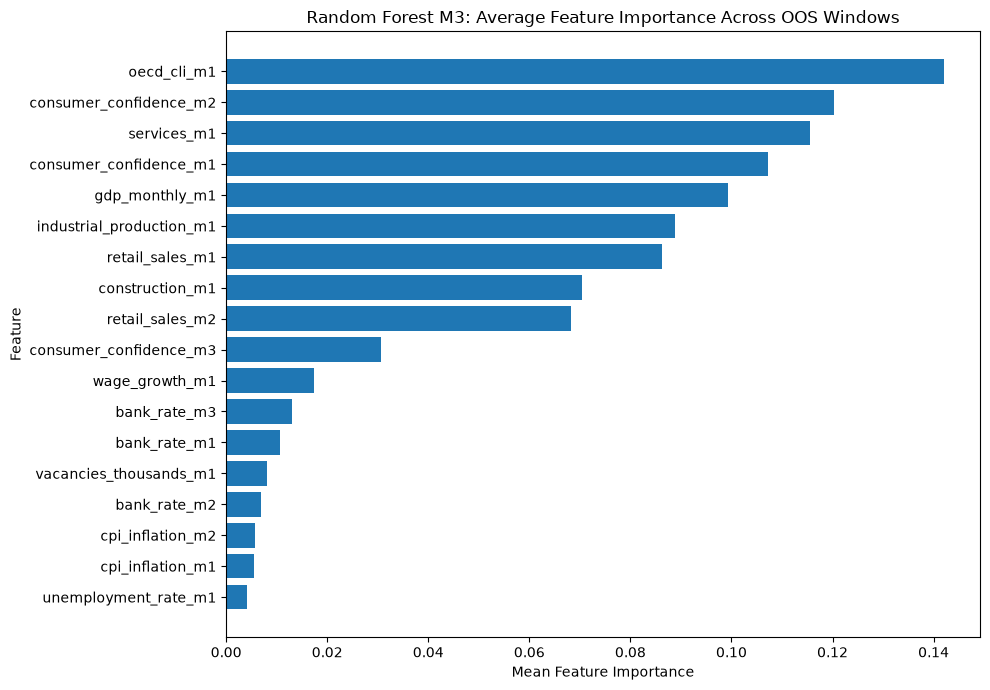

In [14]:
plot_data = (
    rf_importance_summary
    .sort_values("mean_importance", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data.index,
    plot_data["mean_importance"]
)

plt.xlabel("Mean Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Random Forest M3: Average Feature Importance Across OOS Windows"
)

plt.tight_layout()

plt.savefig(
    "../figures/rf_m3_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Random Forest Summary

OECD CLI is the most important predictor on average, followed by consumer confidence, services output and monthly GDP. The ranking suggests that the Random Forest relies primarily on leading and activity indicators, while inflation, interest-rate and labour-market variables contribute relatively less to its forecasts.

Feature importance reflects predictive contribution within the model and should not be interpreted as a causal effect.

## 3. Gradient Boosting SHAP Analysis

SHAP values are used to explain the contribution of individual M3 predictors to Gradient Boosting forecasts. SHAP values are calculated within each expanding forecasting window so that interpretation remains consistent with the out-of-sample evaluation framework.

In [15]:
import shap

gb_feature_cols_m3 = [
    col for col in dataset_m3.columns
    if col not in ["quarter", "gdp_qoq"]
]

# Hyperparameters selected in 05_ml_models.ipynb
best_gb_m3 = {
    "learning_rate": 0.01,
    "max_depth": 1,
    "min_samples_leaf": 3,
    "n_estimators": 200
}

print("Number of M3 features:", len(gb_feature_cols_m3))

Number of M3 features: 18


In [16]:

shap_results = []
feature_value_results = []

for i in range(len(evaluation_sample)):

    forecast_quarter = evaluation_sample.iloc[i]["quarter"]

    gb_train = dataset_m3[
        dataset_m3["quarter"] < forecast_quarter
    ].copy()

    gb_test = dataset_m3[
        dataset_m3["quarter"] == forecast_quarter
    ].copy()

    X_train = gb_train[gb_feature_cols_m3]
    y_train = gb_train["gdp_qoq"]

    X_test = gb_test[gb_feature_cols_m3]

    gb_model = GradientBoostingRegressor(
        random_state=42,
        **best_gb_m3
    )

    gb_model.fit(X_train, y_train)

    explainer = shap.TreeExplainer(gb_model)

    shap_values = explainer.shap_values(X_test)[0]

    shap_row = {
        "quarter": forecast_quarter
    }

    feature_row = {
        "quarter": forecast_quarter
    }

    for feature, shap_value, feature_value in zip(
        gb_feature_cols_m3,
        shap_values,
        X_test.iloc[0].values
    ):
        shap_row[feature] = shap_value
        feature_row[feature] = feature_value

    shap_results.append(shap_row)
    feature_value_results.append(feature_row)

In [17]:
shap_results = pd.DataFrame(shap_results)
feature_value_results = pd.DataFrame(feature_value_results)

print("Number of SHAP windows:", len(shap_results))

display(shap_results.head())
display(feature_value_results.head())

Number of SHAP windows: 37


,quarter,bank_rate_m1,bank_rate_m2,bank_rate_m3,consumer_confidence_m1,consumer_confidence_m2,consumer_confidence_m3,cpi_inflation_m1,cpi_inflation_m2,retail_sales_m1,retail_sales_m2,oecd_cli_m1,gdp_monthly_m1,services_m1,industrial_production_m1,construction_m1,unemployment_rate_m1,vacancies_thousands_m1,wage_growth_m1
0,2017Q1,0.0,0.0,0.0,0.062060,0.057361,0.010011,0.0,0.0,0.0,0.0,0.007020,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2017Q2,0.0,0.0,0.0,0.058572,0.069649,0.009896,0.0,0.0,0.0,0.0,0.015797,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2017Q3,0.0,0.0,0.0,0.058343,0.075572,0.009693,0.0,0.0,0.0,0.0,0.021957,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2017Q4,0.0,0.0,0.0,0.056525,0.076831,0.010270,0.0,0.0,0.0,0.0,0.024067,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2018Q1,0.0,0.0,0.0,0.053496,0.082431,0.009749,0.0,0.0,0.0,0.0,0.027806,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,quarter,bank_rate_m1,bank_rate_m2,bank_rate_m3,consumer_confidence_m1,consumer_confidence_m2,consumer_confidence_m3,cpi_inflation_m1,cpi_inflation_m2,retail_sales_m1,retail_sales_m2,oecd_cli_m1,gdp_monthly_m1,services_m1,industrial_production_m1,construction_m1,unemployment_rate_m1,vacancies_thousands_m1,wage_growth_m1
0,2017Q1,0.25,0.25,0.25,-5.0,-6.0,-6.0,1.8,2.3,-1.1,0.7,101.0282,0.3,0.4,-1.5,1.3,4.6,759.0,2.1
1,2017Q2,0.25,0.25,0.25,-7.0,-5.0,-10.0,2.7,2.9,1.7,-2.0,101.1362,0.5,0.6,0.1,0.7,4.4,787.0,2.2
2,2017Q3,0.25,0.25,0.25,-12.0,-10.0,-9.0,2.6,2.9,-0.1,1.2,101.1259,0.2,0.2,0.4,-0.7,4.3,801.0,2.2
3,2017Q4,0.25,0.50,0.50,-10.0,-12.0,-13.0,3.0,3.1,0.1,0.2,100.8790,0.1,0.1,0.5,-0.6,4.3,816.0,2.6
4,2018Q1,0.50,0.50,0.50,-9.0,-10.0,-7.0,3.0,2.7,-0.9,0.4,100.4200,-0.2,-0.2,1.4,-3.3,4.2,806.0,2.7


In [18]:
shap_feature_cols = [
    col for col in shap_results.columns
    if col != "quarter"
]

mean_abs_shap = (
    shap_results[shap_feature_cols]
    .abs()
    .mean()
    .sort_values(ascending=False)
    .to_frame("mean_abs_shap")
)

display(mean_abs_shap.round(4))

,mean_abs_shap
retail_sales_m1,0.1255
consumer_confidence_m2,0.1114
oecd_cli_m1,0.1002
services_m1,0.0855
retail_sales_m2,0.0588
consumer_confidence_m1,0.0344
industrial_production_m1,0.0322
gdp_monthly_m1,0.0262
construction_m1,0.0139
bank_rate_m3,0.0034


<Figure size 1000x700 with 0 Axes>

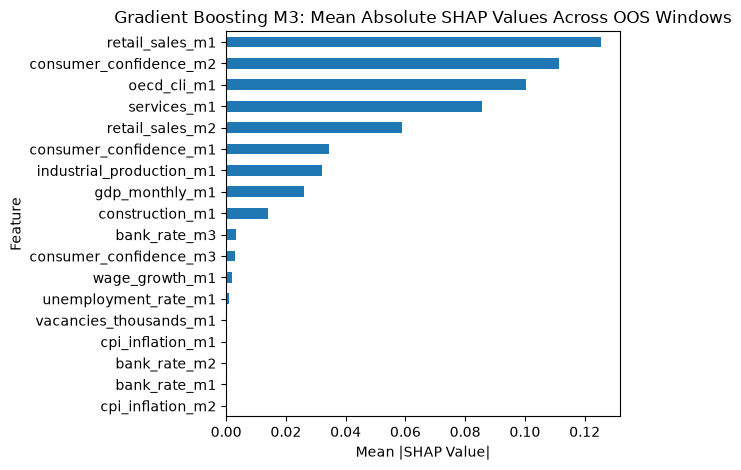

In [19]:
plt.figure(figsize=(10, 7))

mean_abs_shap.sort_values(
    "mean_abs_shap",
    ascending=True
).plot(
    kind="barh",
    legend=False
)

plt.title(
    "Gradient Boosting M3: Mean Absolute SHAP Values Across OOS Windows"
)
plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig(
    "../figures/gb_m3_mean_abs_shap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The SHAP results indicate that Gradient Boosting M3 relies most strongly on retail sales, consumer confidence, the OECD CLI and services activity. Several of these predictors also rank highly in the Random Forest analysis, suggesting that activity, sentiment and leading indicators play an important role across both tree-based models. In contrast, inflation, vacancies and most Bank Rate features make relatively small contributions to the Gradient Boosting forecasts.

In [20]:
shap_results.to_csv(
    "../data/results/gb_m3_shap_values.csv",
    index=False
) 

mean_abs_shap.to_csv(
    "../data/results/gb_m3_mean_abs_shap.csv"
)

In [21]:
shap_matrix = shap_results.drop(columns="quarter")

feature_matrix = feature_value_results.drop(columns="quarter")

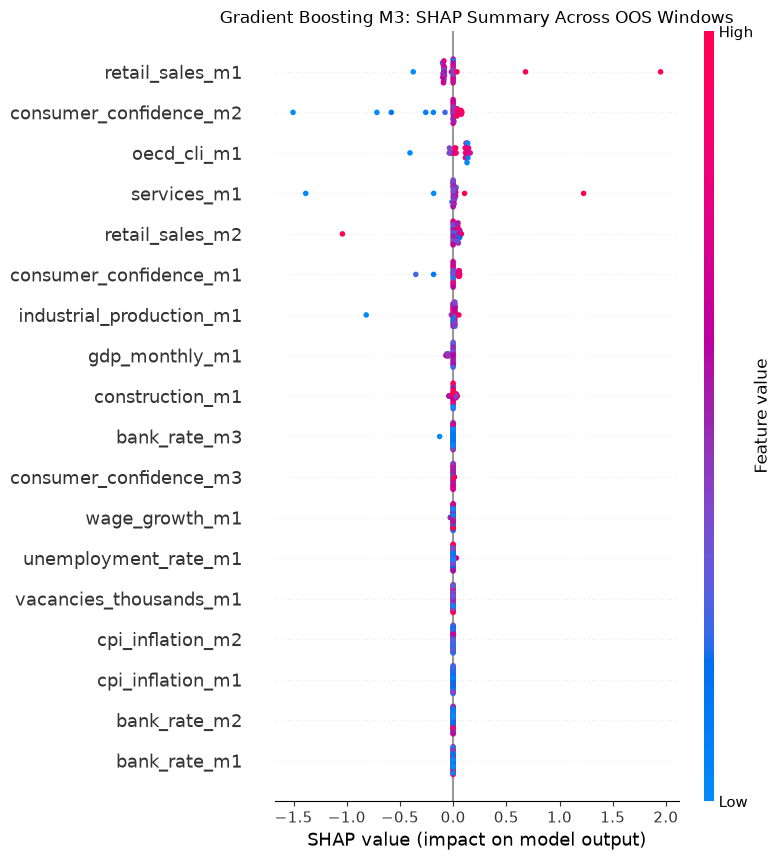

In [22]:
shap.summary_plot(
    shap_matrix.values,
    feature_matrix,
    feature_names=feature_matrix.columns,
    plot_type="dot",
    show=False
)

plt.title(
    "Gradient Boosting M3: SHAP Summary Across OOS Windows"
)

plt.tight_layout()

plt.savefig(
    "../figures/gb_m3_shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### SHAP Summary

The SHAP analysis confirms that Gradient Boosting relies primarily on retail sales, consumer confidence, the OECD CLI and services activity. Lower confidence, weaker leading indicators and weak services activity generally push GDP nowcasts downward, while stronger values can contribute positively.

The effects are nonlinear and concentrated in particular forecasting periods, with many predictors having little influence in most quarters but substantial effects during selected episodes. Inflation, vacancies and most Bank Rate features contribute relatively little to the Gradient Boosting forecasts.